# 05 — Error analysis

This notebook audits the saved test predictions: confusion matrices, bacterial-vs-viral errors, paired bootstrap, calibration, misclassified examples, and Grad-CAM. All analysis uses saved files; nothing is retrained.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


In [2]:
import pandas as pd
base = pd.read_csv("results/baseline/seed42/predictions_test.csv")
prop = pd.read_csv("results/proposed/seed42/predictions_test.csv")
print("baseline macro errors:", (base.true_label != base.predicted_label).sum(), "/", len(base))
print("proposed macro errors:", (prop.true_label != prop.predicted_label).sum(), "/", len(prop))

baseline macro errors: 245 / 624
proposed macro errors: 102 / 624


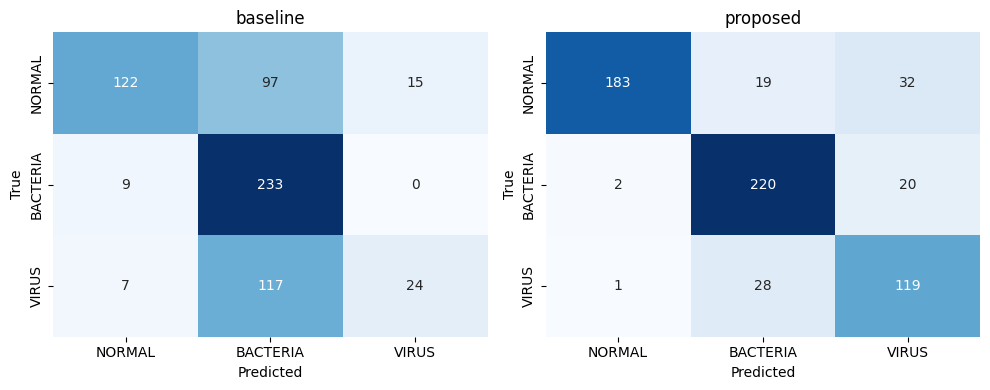

In [3]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

names = ["NORMAL", "BACTERIA", "VIRUS"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, df) in zip(axes, [("baseline", base), ("proposed", prop)]):
    cm = confusion_matrix(df.true_label, df.predicted_label, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.tight_layout()
plt.show()

In [4]:
import json
print(json.dumps(json.load(open("results/bacterial_viral_confusion.json")), indent=2))

{
  "baseline": {
    "bacterial_true": 233,
    "viral_true": 141,
    "bacterial_to_viral": 0,
    "viral_to_bacterial": 117,
    "bacterial_to_viral_rate": 0.0,
    "viral_to_bacterial_rate": 0.8297872340425532
  },
  "proposed": {
    "bacterial_true": 240,
    "viral_true": 147,
    "bacterial_to_viral": 20,
    "viral_to_bacterial": 28,
    "bacterial_to_viral_rate": 0.08333333333333333,
    "viral_to_bacterial_rate": 0.19047619047619047
  }
}


In [5]:
print(json.dumps(json.load(open("results/bootstrap_comparison.json")), indent=2)[:3000])

{
  "per_seed": {
    "42": {
      "n_boot": 2000,
      "baseline_macro_f1_ci95": [
        0.49005343226625625,
        0.5693356555466821
      ],
      "proposed_macro_f1_ci95": [
        0.7961449736280393,
        0.8581952368661439
      ],
      "difference_mean": 0.29740235577460783,
      "difference_ci95": [
        0.2542934264866456,
        0.34143067945395833
      ],
      "probability_proposed_better": 1.0,
      "observed_baseline_macro_f1": 0.5296469986241208,
      "observed_proposed_macro_f1": 0.8273167182387425
    },
    "43": {
      "n_boot": 2000,
      "baseline_macro_f1_ci95": [
        0.49381729791564827,
        0.5669368883551004
      ],
      "proposed_macro_f1_ci95": [
        0.8025096625780987,
        0.8626849568448305
      ],
      "difference_mean": 0.3043618550598308,
      "difference_ci95": [
        0.2600010900681128,
        0.3468321004483832
      ],
      "probability_proposed_better": 1.0,
      "observed_baseline_macro_f1": 0.529931

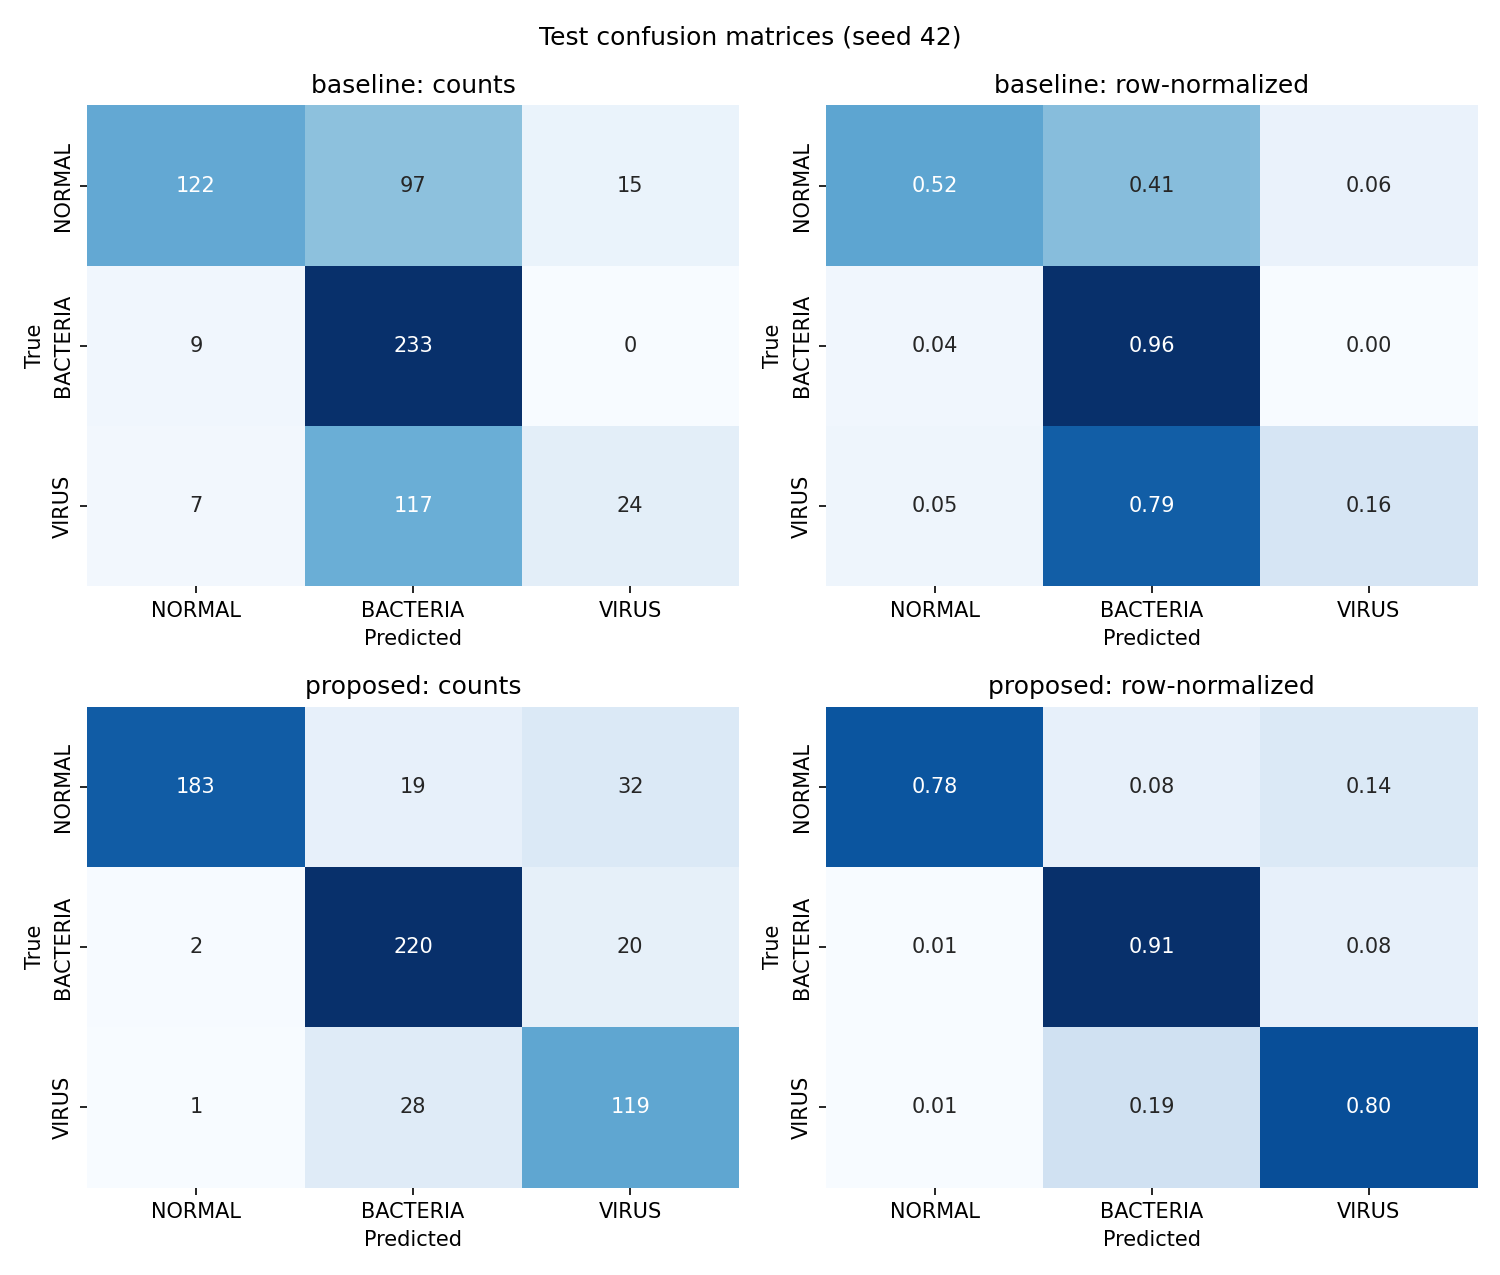

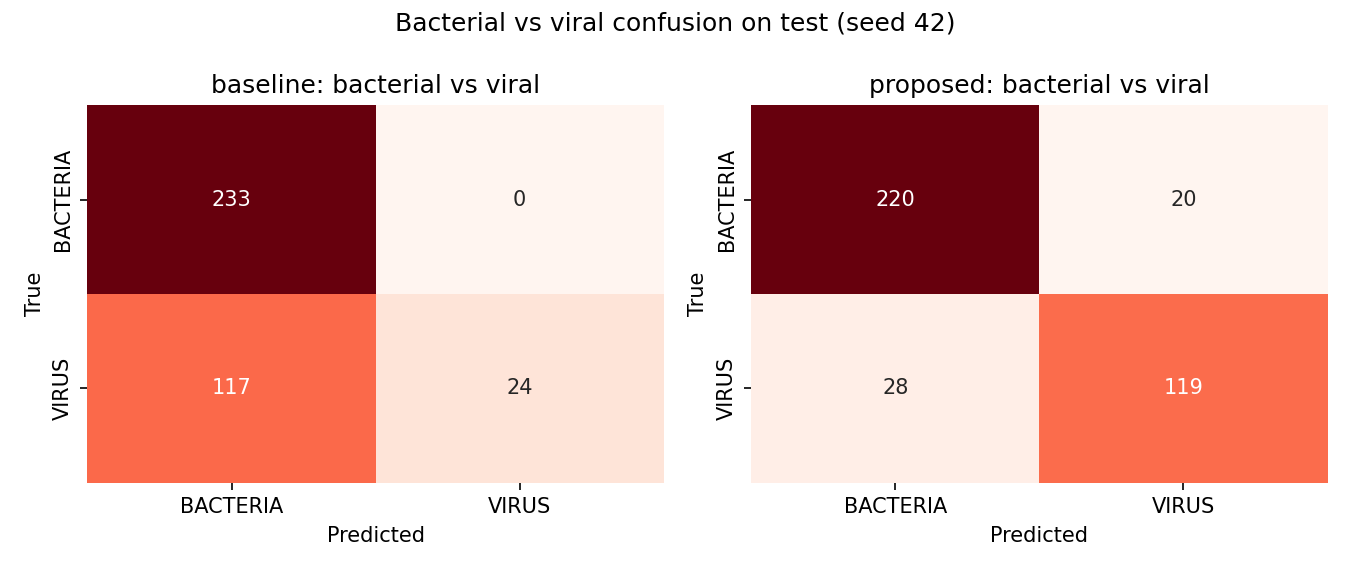

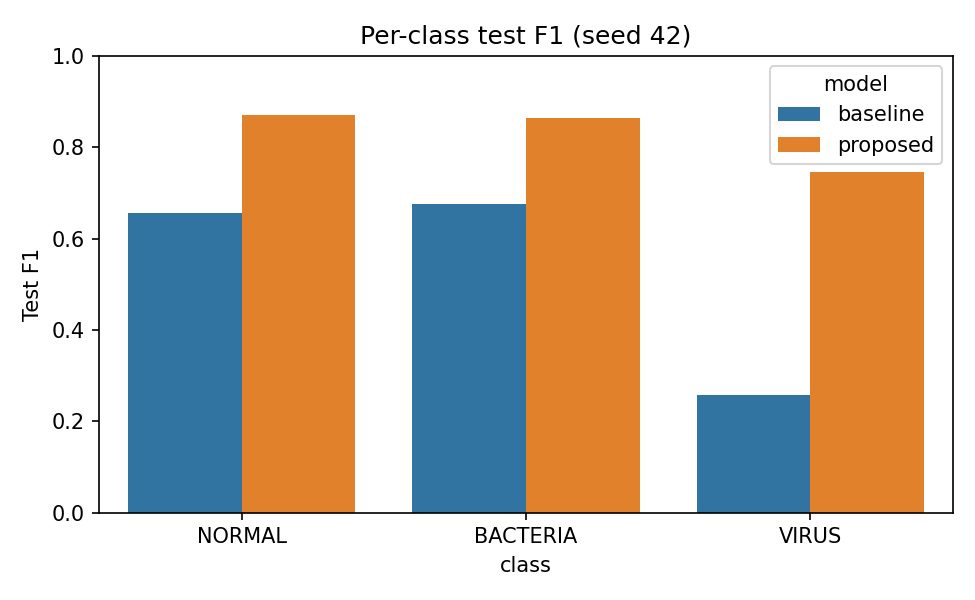

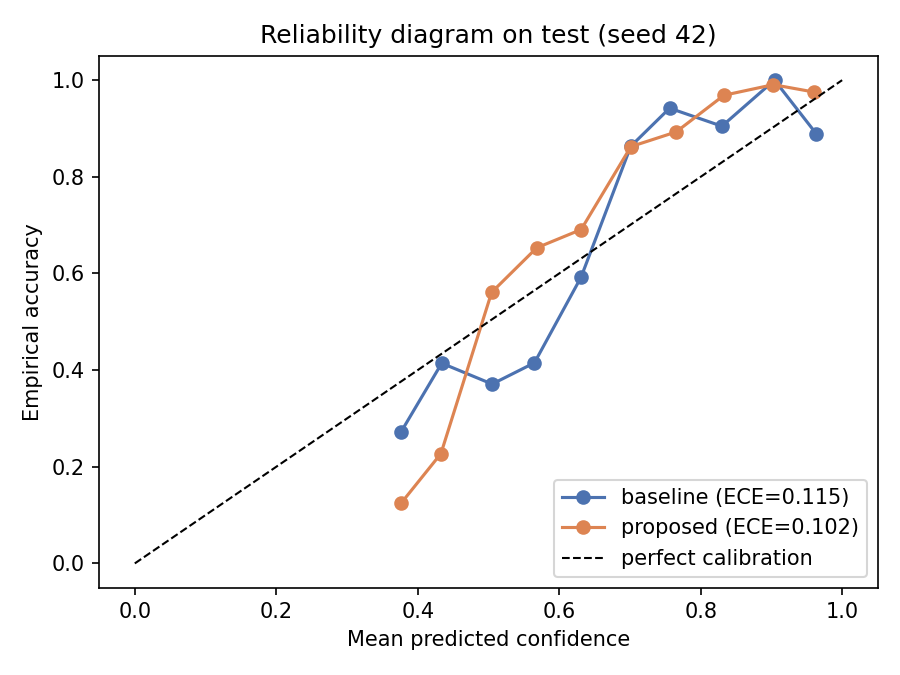

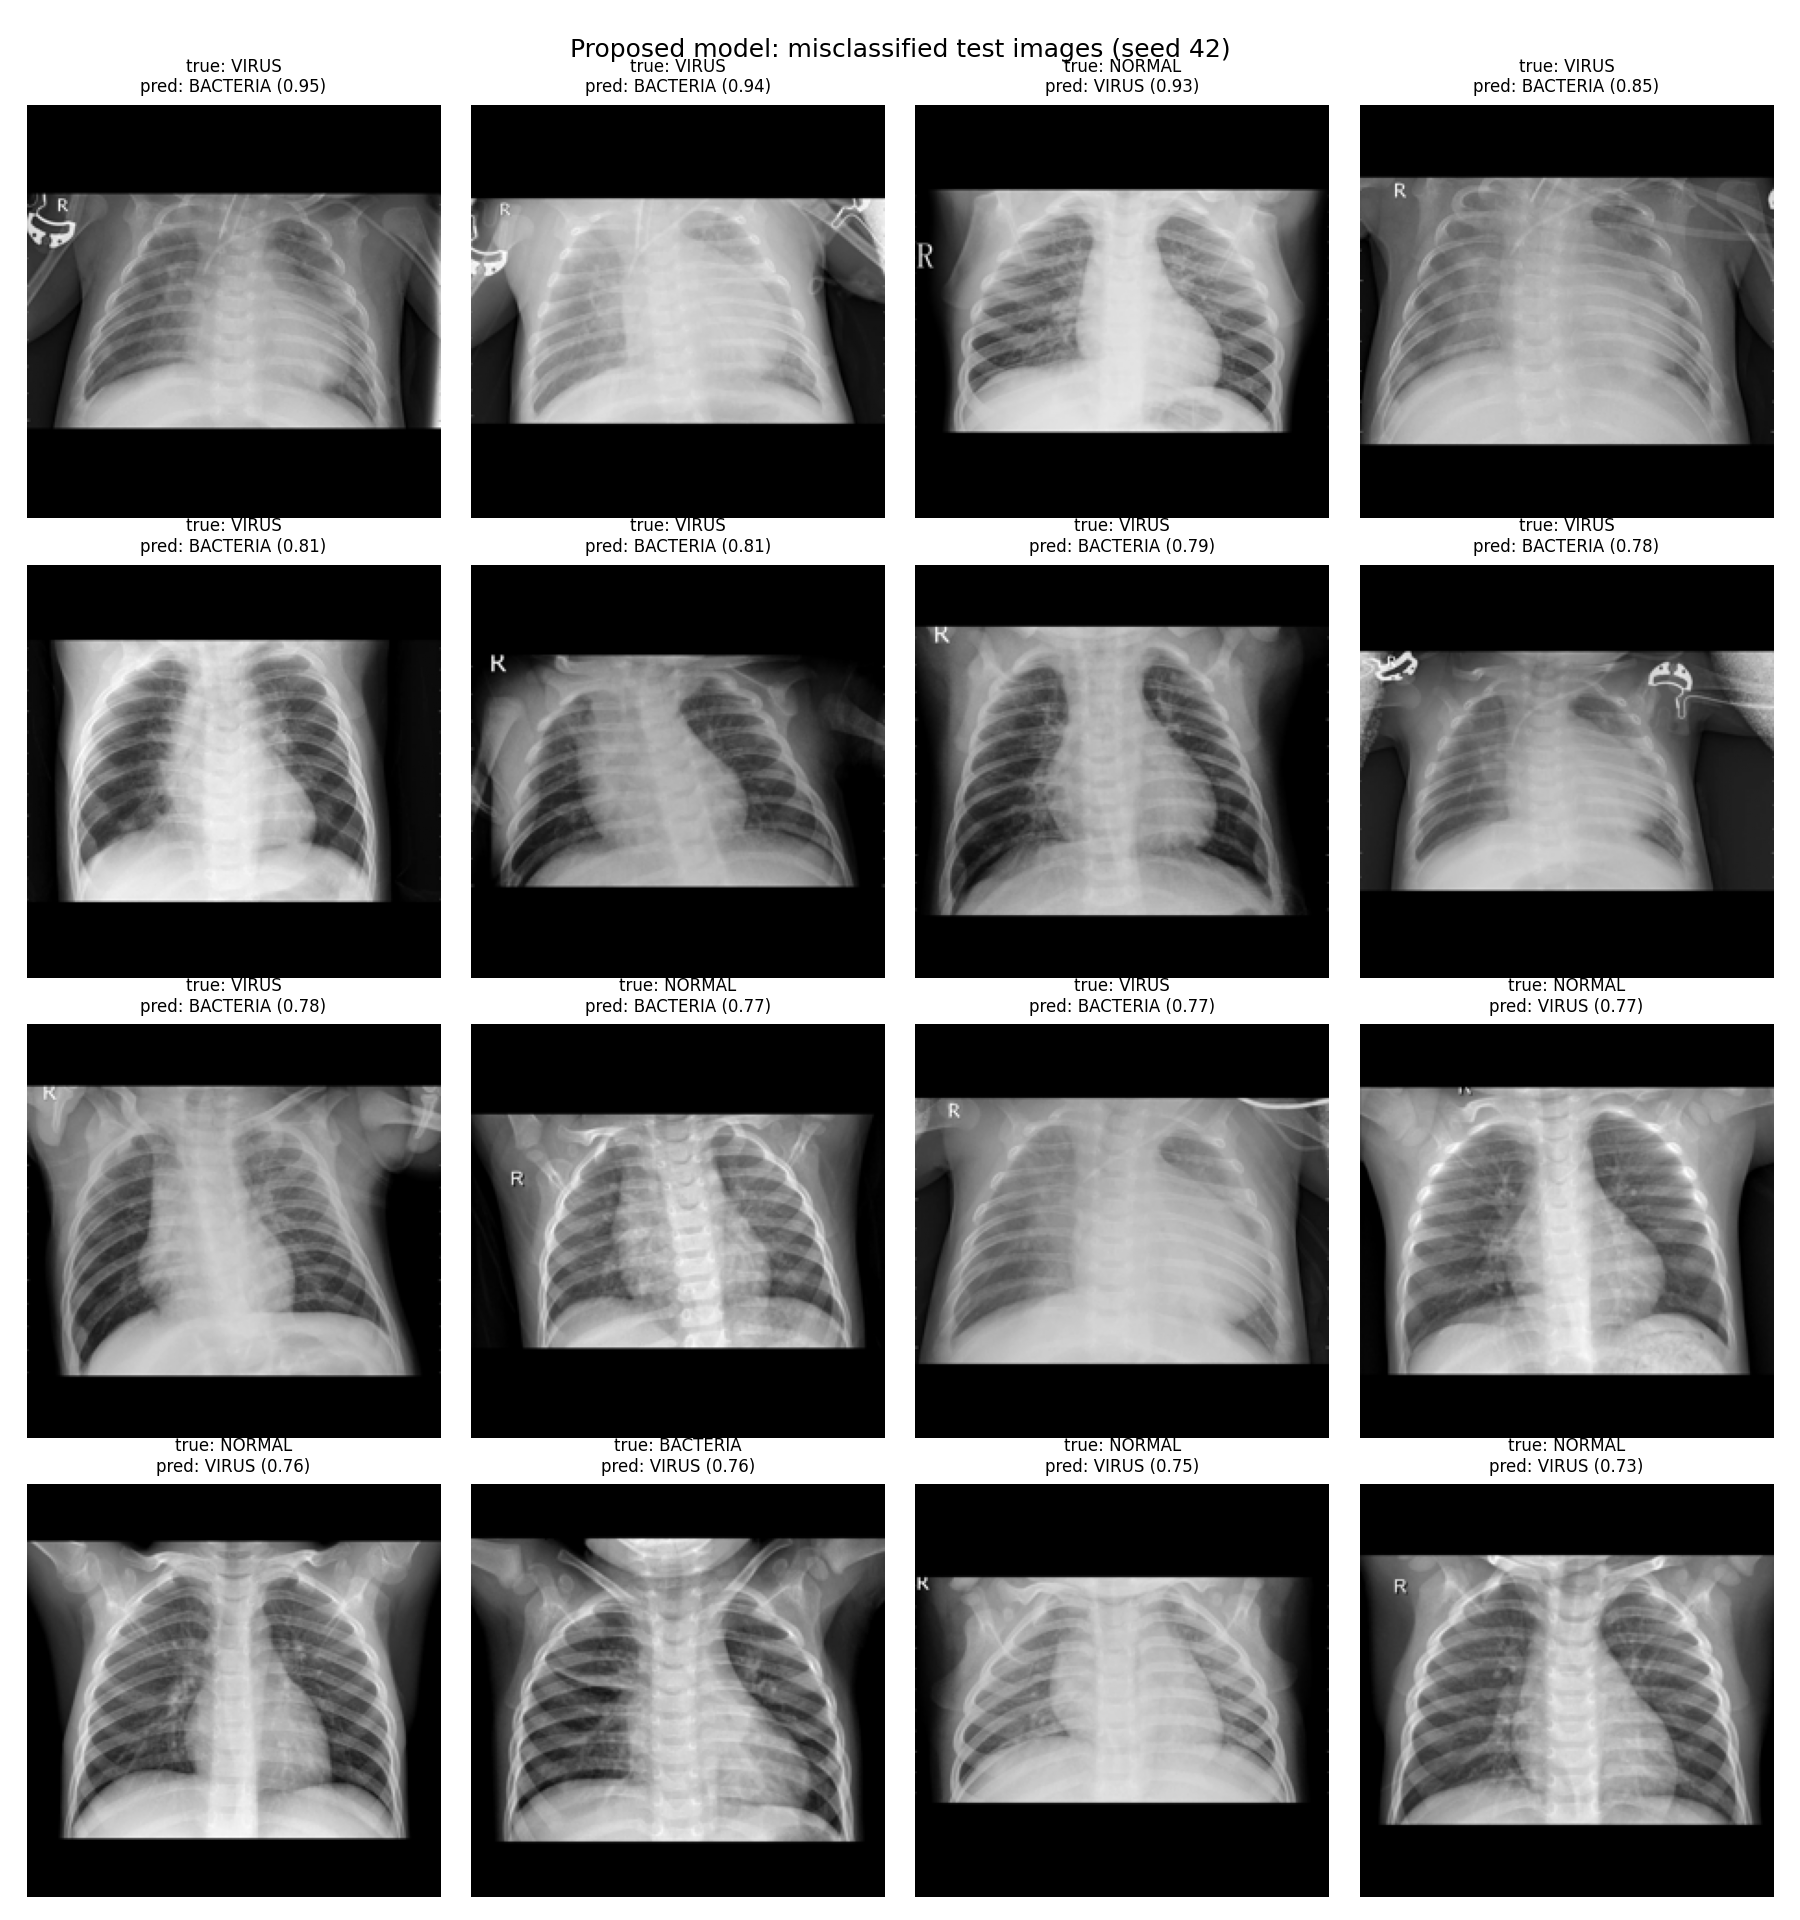

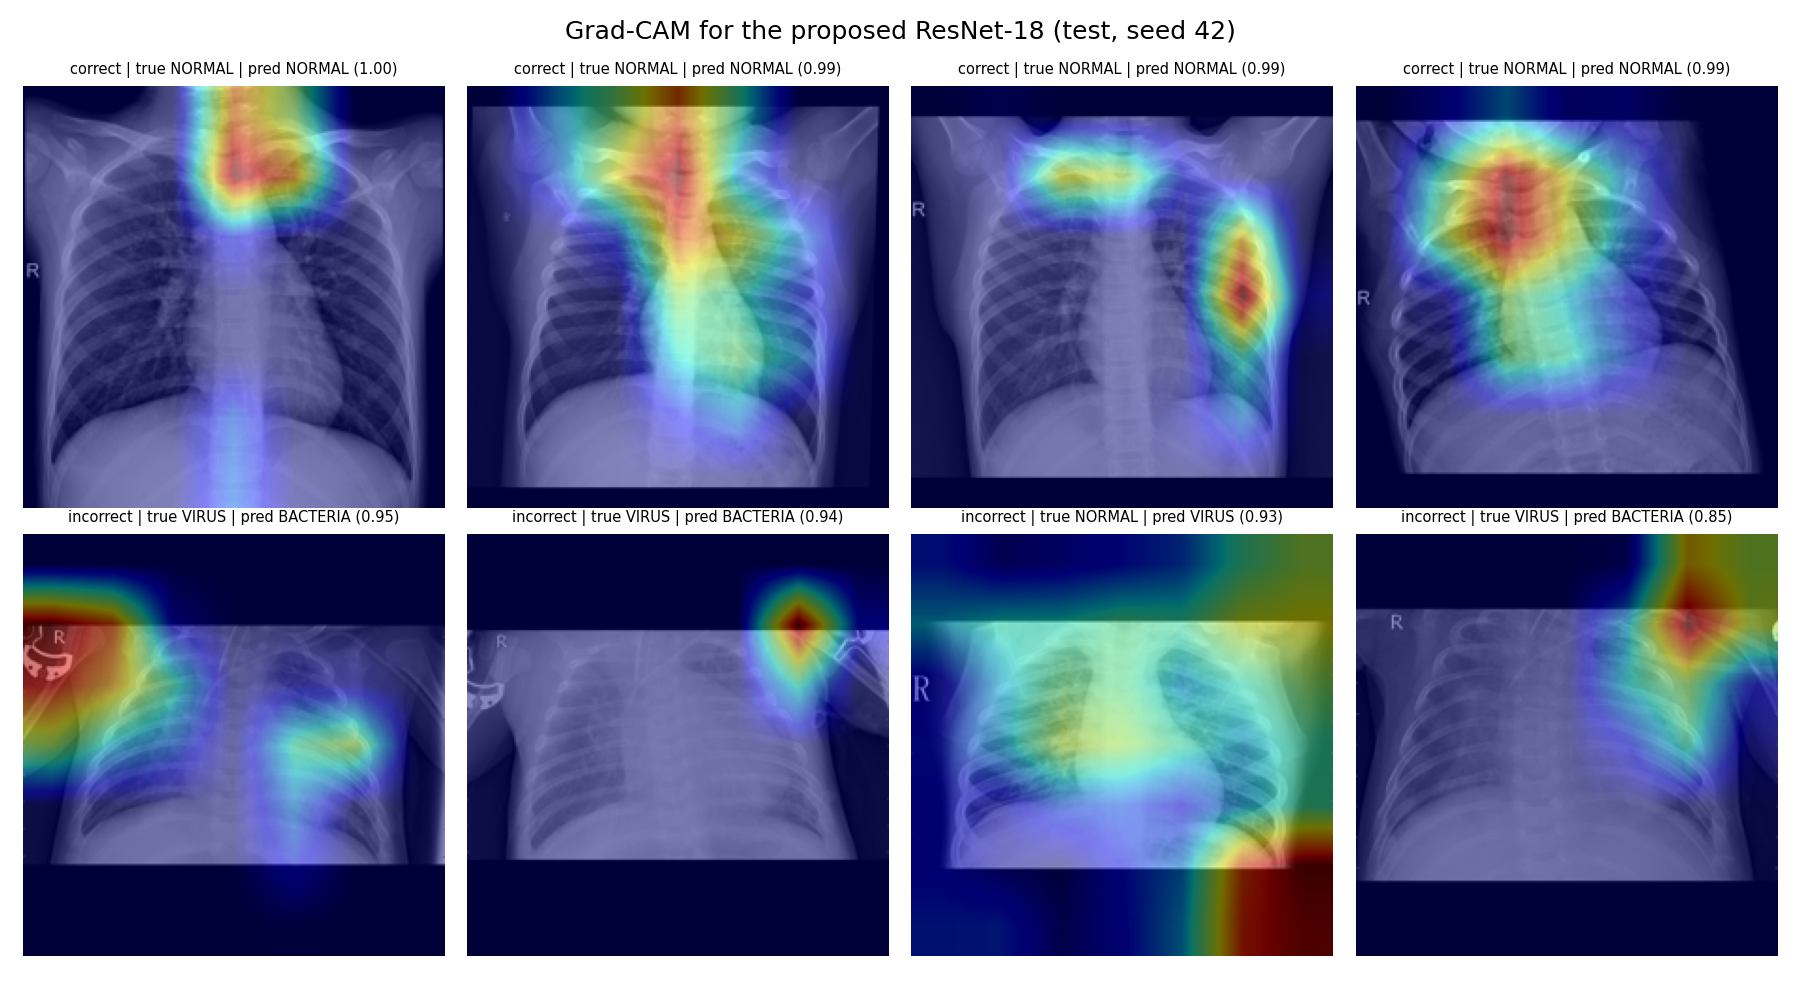

In [6]:
from IPython.display import Image, display
for name in (
    "confusion_matrices_baseline_vs_proposed.png",
    "bacterial_viral_confusion.png",
    "per_class_f1.png",
    "reliability_diagram.png",
    "proposed_misclassified_test.png",
    "gradcam_proposed_test.png",
):
    display(Image(filename=f"results/figures/{name}"))

## Interpretation

- The proposed model reduces total test errors and substantially reduces viral-to-bacterial confusion.
- VIRUS remains the lowest-F1 class for both models; bacterial and viral pneumonia can look similar on pediatric radiographs.
- AUROC is high while thresholded macro-F1 is lower, especially for the baseline. Calibration is moderate, so probabilities are not clinical risks.
- Grad-CAM shows that some correct predictions attend to lung/mediastinal regions, but several errors focus on borders or text markers. It is a qualitative diagnostic, not a validated localization method.